# Projeto de Inteligência Artificial - 7K SI Noite - Prof. Dr. Leandro Zerbinatti
### Universidade Presbiteriana Mackenzie - Faculdade de Computação e Informática

**Sentinela de Risco: Classificação de Risco Financeiro de Empresas Brasileiras com Machine Learning**

Demonstração interativa (Google Colab) do pipeline de Machine Learning da N2.

**Integrantes do grupo:**
- Cristiano Morales — RA 10437953 — 10437953@mackenzista.com.br
- Caio Carames — RA 10308718 — 10308718@mackenzista.com.br
- Leonardo Tonon — RA 10426930 — 10426930@mackenzista.com.br
- Ali Ahmad — RA 10427712 — 10427712@mackenzista.com.br

**Histórico de atualizações:**
- 2026-11-14 | Cristiano Morales | Criação do notebook de demonstração para Google Colab, usado na gravação do vídeo da N2.

Este notebook carrega o dataset **diretamente do repositório público no GitHub** (não precisa fazer upload de nenhum arquivo) e reproduz, célula a célula, a classificação de risco financeiro e a regressão do resultado líquido treinadas em `ml/treinar_modelos.py`, incluindo o estudo de caso nas 4 varejistas.

➡️ **Para rodar:** no menu, `Ambiente de execução` → `Executar tudo` (ou `Runtime` → `Run all`).

## 1. Carregar o dataset (474 empresas, CVM DFP 2023)

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

URL_DATASET = "https://raw.githubusercontent.com/CristianoMorales/Projeto_IA/main/dataset/cvm_dfp_2023_empresas.csv"
df = pd.read_csv(URL_DATASET)
print(f"Dataset carregado: {len(df)} empresas, {df.shape[1]} colunas")
df.head(10)

Dataset carregado: 474 empresas, 14 colunas


,CNPJ_CIA,DENOM_CIA,CD_CVM,receita_liquida,resultado_liquido,passivo_total,patrimonio_liquido,ativo_total,margem_liquida_pct,alavancagem,roe_pct,endividamento_ativo_pct,patrimonio_liquido_negativo,risco_financeiro
0,08.773.135/0001-00,2W ECOBANK S.A. - EM RECUPERAÇÃO JUDICIAL,25224,1097.488,-222.647,2951.570,-77.416,2951.570,-20.286964,NaN,NaN,100.0,1,alto
1,08.827.501/0001-58,AEGEA SANEAMENTO E PARTICIPAÇÕES S.A.,23396,8806.540,1596.362,34486.194,10956.308,34486.194,18.127006,3.147611,14.570255,100.0,0,medio
2,12.528.708/0001-07,AERIS IND. E COM. DE EQUIP. PARA GER. DE ENG. ...,25283,2831.915,-106.567,4014.481,1138.258,4014.481,-3.763072,3.526864,-9.362289,100.0,0,medio
3,21.240.146/0001-84,AGROGALAXY PARTICIPAÇÕES S.A. - EM RECUPERAÇÃO...,25658,9399.096,-367.292,7714.016,1136.662,7714.016,-3.907738,6.786552,-32.313212,100.0,0,medio
4,23.438.929/0001-00,ALARES INTERNET PARTICIPAÇÕES S/A,25194,567.852,-157.366,2135.917,460.122,2135.917,-27.712503,4.642067,-34.200929,100.0,0,medio
5,71.208.516/0001-74,ALGAR TELECOM S/A,21032,2746.728,-149.613,7394.310,1490.786,7394.310,-5.446954,4.960008,-10.035847,100.0,0,medio
6,61.156.931/0001-78,ALIPERTI S.A.,12823,34.511,16.178,491.535,222.832,491.535,46.877807,2.205855,7.260178,100.0,0,baixo
7,42.771.949/0001-35,ALLIANÇA SAÚDE E PARTICIPAÇÕES S.A.,24058,1179.584,-218.559,2669.811,943.992,2669.811,-18.528481,2.828214,-23.152633,100.0,0,medio
8,20.247.322/0001-47,ALLIED TECNOLOGIA S.A.,25330,5854.915,122.444,3395.751,1599.166,3395.751,2.091303,2.123451,7.656741,100.0,0,baixo
9,05.878.397/0001-32,ALLOS S.A.,22357,2712.274,3493.910,27659.095,15104.732,27659.095,128.818475,1.831154,23.131228,100.0,0,baixo


## 2. Visão geral: distribuição de risco financeiro

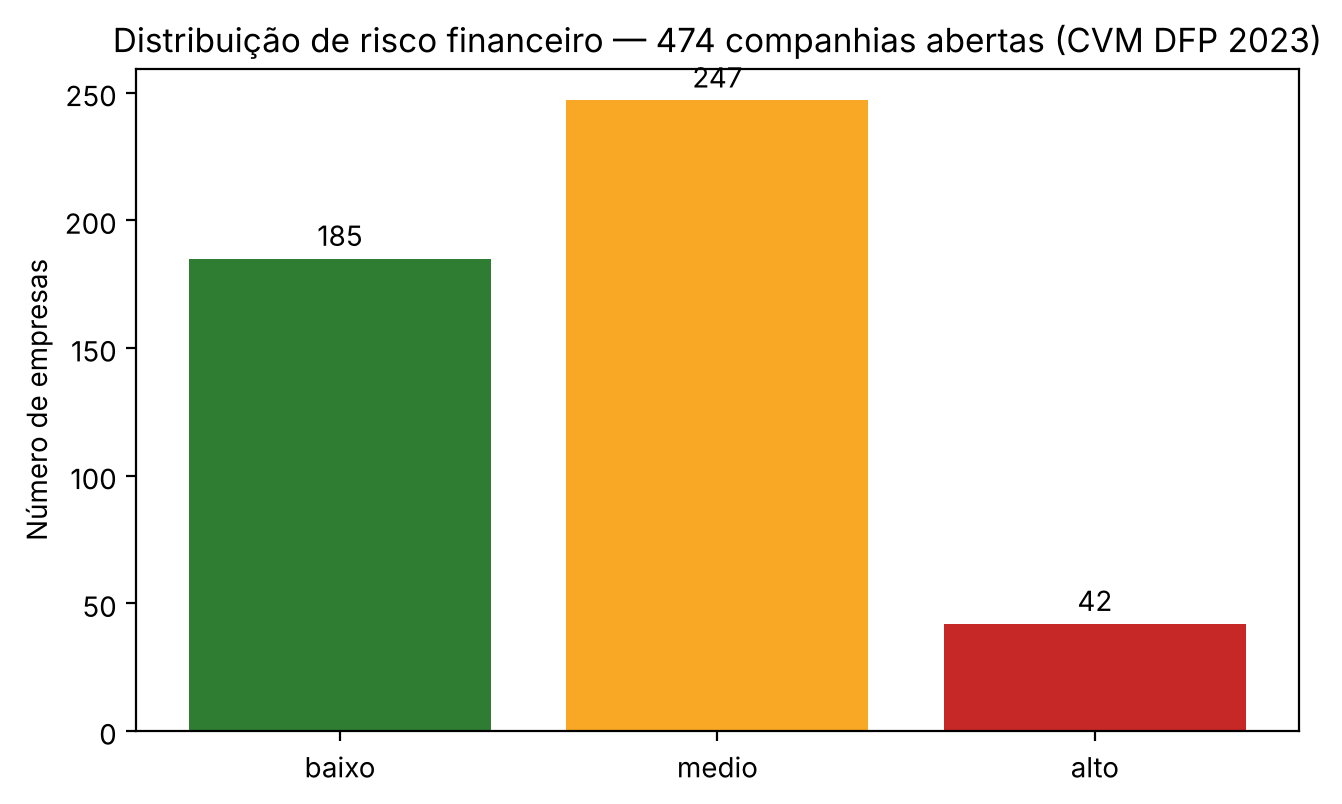

risco_financeiro
baixo    185
medio    247
alto      42


In [ ]:
CORES_RISCO = {"baixo": "#2e7d32", "medio": "#f9a825", "alto": "#c62828"}
contagem = df["risco_financeiro"].value_counts().reindex(["baixo", "medio", "alto"])

fig, ax = plt.subplots(figsize=(7.5, 4.3))
ax.bar(contagem.index, contagem.values, color=[CORES_RISCO[c] for c in contagem.index])
for i, v in enumerate(contagem.values):
    ax.text(i, v + 5, str(v), ha="center")
ax.set_title(f"Distribuição de risco financeiro — {len(df)} companhias abertas (CVM DFP 2023)")
ax.set_ylabel("Número de empresas")
plt.show()

print(contagem.to_string())

## 3. Classificação: prever o risco financeiro (baixo / médio / alto)

**Features usadas (deliberadamente):** apenas `receita_liquida`, `ativo_total` e `passivo_total` — isto é, variáveis de "tamanho" do balanço. Patrimônio líquido, resultado líquido, margem e alavancagem são **excluídos propositalmente**, pois são usados para construir o próprio rótulo de risco (ver Seção 3.4 do relatório — evitar vazamento de rótulo / tarefa circular).

Regressão Logística — acurácia (5-fold CV): 21.5%
              precision    recall  f1-score   support

        alto       0.10      0.83      0.18        42
       baixo       0.44      0.14      0.21       185
       medio       0.61      0.17      0.27       247

    accuracy                           0.22       474
   macro avg       0.38      0.38      0.22       474
weighted avg       0.50      0.22      0.24       474



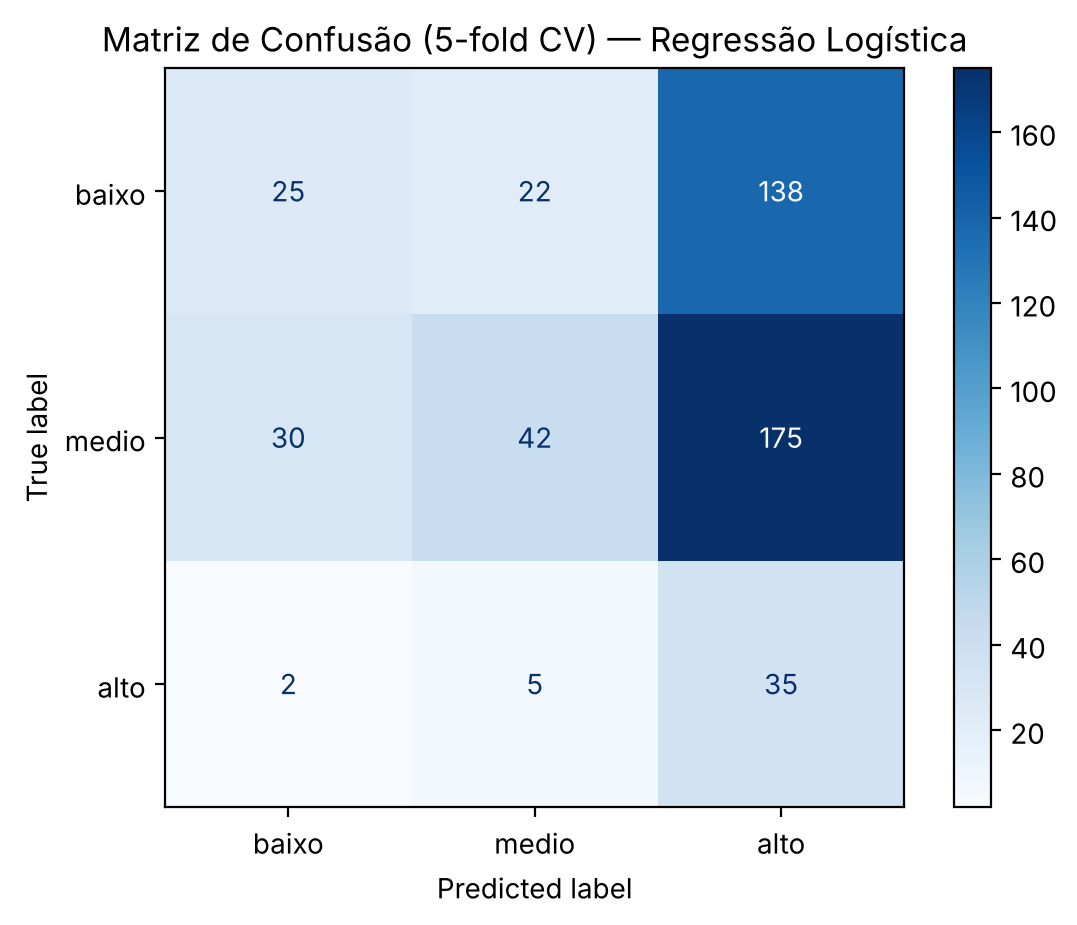

Random Forest — acurácia (5-fold CV): 47.7%
              precision    recall  f1-score   support

        alto       0.16      0.24      0.19        42
       baixo       0.45      0.48      0.46       185
       medio       0.58      0.52      0.55       247

    accuracy                           0.48       474
   macro avg       0.40      0.41      0.40       474
weighted avg       0.50      0.48      0.48       474



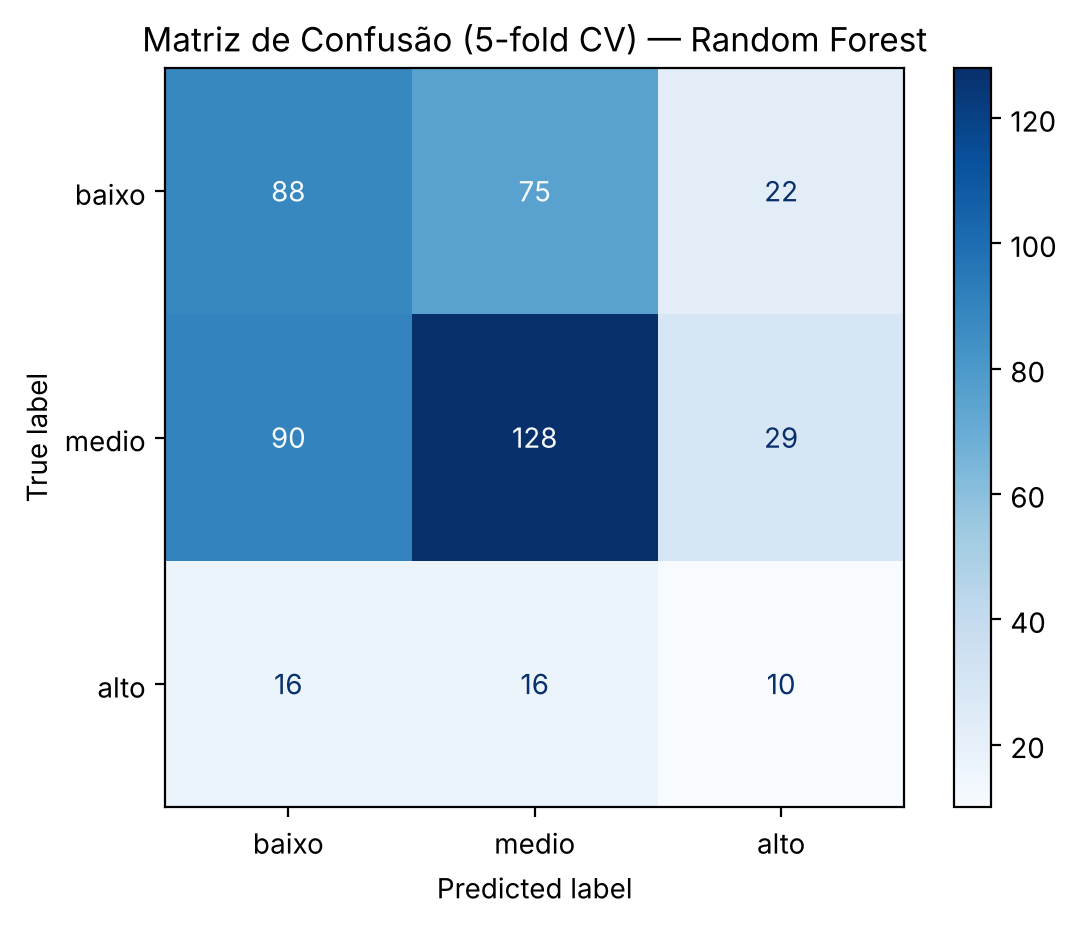

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

FEATURES = ["receita_liquida", "ativo_total", "passivo_total"]
SEED = 42

df_clf = df.dropna(subset=FEATURES + ["risco_financeiro"])
X = df_clf[FEATURES].values
y = df_clf["risco_financeiro"].values
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

modelos_clf = {
    "Regressão Logística": make_pipeline(
        StandardScaler(), LogisticRegression(max_iter=2000, random_state=SEED, class_weight="balanced")
    ),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=SEED, class_weight="balanced"),
}

modelos_treinados = {}
for nome, modelo in modelos_clf.items():
    y_pred = cross_val_predict(modelo, X, y, cv=cv)
    acc = accuracy_score(y, y_pred)
    print("=" * 70)
    print(f"{nome} — acurácia (5-fold CV): {acc:.1%}")
    print(classification_report(y, y_pred, zero_division=0))

    modelo.fit(X, y)  # versão final, treinada no dataset inteiro
    modelos_treinados[nome] = modelo

    cm = confusion_matrix(y, y_pred, labels=["baixo", "medio", "alto"])
    disp = ConfusionMatrixDisplay(cm, display_labels=["baixo", "medio", "alto"])
    disp.plot(cmap="Blues", values_format="d")
    disp.ax_.set_title(f"Matriz de Confusão (5-fold CV) — {nome}")
    plt.show()

### Importância das variáveis (Random Forest)

In [ ]:
rf = modelos_treinados["Random Forest"]
importancias = pd.Series(rf.feature_importances_, index=FEATURES).sort_values(ascending=False)
importancias_pct = (importancias * 100).round(1).astype(str) + "%"
importancias_pct

receita_liquida    35.1%
passivo_total      32.5%
ativo_total        32.4%
dtype: str

## 4. Regressão: prever o resultado líquido (R$ milhões)

In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import KFold

df_reg = df.dropna(subset=FEATURES + ["resultado_liquido"])
Xr = df_reg[FEATURES].values
yr = df_reg["resultado_liquido"].values
cv_reg = KFold(n_splits=5, shuffle=True, random_state=SEED)

modelos_reg = {
    "Regressão Linear": make_pipeline(StandardScaler(), LinearRegression()),
    "Random Forest Regressor": RandomForestRegressor(n_estimators=300, random_state=SEED),
}

resultados_reg = []
for nome, modelo in modelos_reg.items():
    y_pred = cross_val_predict(modelo, Xr, yr, cv=cv_reg)
    mae = mean_absolute_error(yr, y_pred)
    r2 = r2_score(yr, y_pred)
    resultados_reg.append({"Modelo": nome, "MAE (R$ milhões)": round(mae, 1), "R²": round(r2, 3)})

pd.DataFrame(resultados_reg)

,Modelo,MAE (R$ milhões),R²
0,Regressão Linear,1971.4,0.905
1,Random Forest Regressor,2034.7,0.383


⚠️ **Leitura com cautela:** o R² da Regressão Linear é inflado por efeito de escala — o dataset mistura empresas de portes extremamente diferentes (de companhias pequenas a grandes bancos), e parte da variância é explicada simplesmente pelo fato de empresas maiores terem lucros/prejuízos proporcionalmente maiores. Ver discussão completa na Seção 6.2 do relatório.

## 5. Estudo de caso: as 4 varejistas analisadas desde a N1

Aplicando o modelo de Random Forest (treinado nas 474 empresas) às quatro varejistas do dataset histórico da N1 — comparando a predição automática com o risco real de cada uma.

In [ ]:
import re

EMPRESAS_VAREJO = ["AMERICANAS", "MAGAZINE LUIZA", "VIA S.A", "VIA VAREJO", "CASAS BAHIA", "LOJAS RENNER"]
padrao = "|".join(re.escape(a) for a in EMPRESAS_VAREJO)
casos = df[df["DENOM_CIA"].str.contains(padrao, case=False, na=False)].copy()
casos["risco_previsto_rf"] = modelos_treinados["Random Forest"].predict(casos[FEATURES].values)
casos["acertou"] = np.where(casos["risco_financeiro"] == casos["risco_previsto_rf"], "✅", "❌")

tabela = casos[["DENOM_CIA", "resultado_liquido", "risco_financeiro", "risco_previsto_rf", "acertou"]].rename(
    columns={
        "DENOM_CIA": "Empresa",
        "resultado_liquido": "Resultado líquido (R$ mi)",
        "risco_financeiro": "Risco real",
        "risco_previsto_rf": "Risco previsto (modelo)",
        "acertou": "Acertou?",
    }
)
tabela

,Empresa,Resultado líquido (R$ mi),Risco real,Risco previsto (modelo),Acertou?
20,AMERICANAS S.A. - EM RECUPERAÇÃO JUDICIAL,-2272.000,alto,alto,✅
217,GRUPO CASAS BAHIA S.A.,-2625.000,medio,medio,✅
287,LOJAS RENNER S.A.,976.259,baixo,baixo,✅
294,MAGAZINE LUIZA S.A.,-979.104,medio,medio,✅


In [ ]:
acertos = (casos["risco_financeiro"] == casos["risco_previsto_rf"]).sum()
print(f"O modelo acertou {acertos} de {len(casos)} classificações de risco das 4 varejistas do estudo de caso,")
print("usando apenas receita líquida, ativo total e passivo total — sem olhar diretamente patrimônio líquido ou resultado.")

O modelo acertou 4 de 4 classificações de risco das 4 varejistas do estudo de caso,
usando apenas receita líquida, ativo total e passivo total — sem olhar diretamente patrimônio líquido ou resultado.
